# TSP + QAOA – library

Reusable functions for solving the travelling salesperson problem (TSP) with QAOA, organised by module:

| Section | What it contains |
|---|---|
| **1. data** | `Instance`, `load_instance` – load locations (the first `n`, or chosen `nodes`) and the distance matrix |
| **2. encoding** | `PositionEncoding` – the **only** place that knows which qubit means which customer at which position |
| **3. classical** | `route_length`, `all_routes`, `brute_force` – classical reference |
| **4. problem** | `build_qp`, `to_hamiltonian` – TSP → optimization problem → QUBO → Ising Hamiltonian |
| **5. qaoa** | `build_ansatz`, `optimize`, `probabilities` – circuit, parameter optimization, simulation |
| **6. analysis** | `evaluate`, `QAOAResult` – how good the QAOA output is |
| **7. plotting** | `plot_route`, `plot_distribution` |
| **8. tests** | consistency checks of the encoding and the Hamiltonian |
| **9. example** | the whole pipeline on 5 Tallinn locations |

**Design rules:** no global variables (everything a function needs is a parameter), functions return data instead of
printing, and the encoding is passed around as an object, so it can later be swapped for a different one
(e.g. a compact 12-qubit encoding or two vehicles) without touching the rest.

Other notebooks can load it with `RUN_EXAMPLE = False` followed by `%run -i tsp_library.ipynb` (this skips the example in section 9).

In [59]:
from __future__ import annotations

import json
from dataclasses import dataclass, field
from itertools import permutations
from typing import Iterator, Sequence

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

from qiskit import transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp, Statevector

from qiskit_addon_opt_mapper import OptimizationProblem
from qiskit_addon_opt_mapper.converters import OptimizationProblemToQubo
from qiskit_addon_opt_mapper.translators import to_ising

Route = tuple[int, ...]   # e.g. (0, 3, 4, 1, 2, 0) – starts and ends at the depot

## 1. data

In [60]:
@dataclass
class Instance:
    """One TSP instance: location names, coordinates and the distance matrix (km).

    Locations are renumbered 0..n-1 (0 = depot); `ids[i]` is the index of location i in the data file.
    """
    names: list[str]
    lat: np.ndarray
    lon: np.ndarray
    distances: np.ndarray   # distances[i, j] = driving distance from i to j in km
    ids: list[int]          # original indices in the data file

    @property
    def n(self) -> int:
        return len(self.names)

    def __str__(self) -> str:
        lines = [f"{self.n} locations (index → data file index: name)"]
        lines += [f"  {i} → {orig}: {name}" + ("  [depot]" if i == 0 else "")
                  for i, (orig, name) in enumerate(zip(self.ids, self.names))]
        return "\n".join(lines)


def load_instance(path: str, n: int | None = None, nodes: Sequence[int] | None = None,
                  symmetric: bool = False) -> Instance:
    """Load locations from the OSRM JSON file (distances in metres → km).

    Choose the locations in one of two ways:
      n=5                  – the first 5 locations of the file
      nodes=[0, 3, 4, 7]   – exactly these locations; the FIRST one becomes the depot (index 0)
    The selected locations are renumbered 0..len(nodes)-1, the original indices are kept in `Instance.ids`.

    symmetric=True keeps only the values above the main diagonal of the ORIGINAL matrix and mirrors them,
    so that the trip i → j is as long as j → i (independent of the order in `nodes`).
    """
    if (n is None) == (nodes is None):
        raise ValueError("Give exactly one of `n` or `nodes`.")
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    full = np.array(data["distances"], dtype=float) / 1000
    total = len(data["points"])

    nodes = list(range(n)) if nodes is None else [int(i) for i in nodes]
    if len(nodes) < 2:
        raise ValueError("At least 2 locations are needed.")
    if len(set(nodes)) != len(nodes):
        raise ValueError(f"Duplicate locations in nodes={nodes}.")
    if not all(0 <= i < total for i in nodes):
        raise ValueError(f"Location indices must be between 0 and {total - 1}, got {nodes}.")
    points = [data["points"][i] for i in nodes]
    coords = {(p["lat"], p["lon"]) for p in points}
    if len(coords) != len(points):
        raise ValueError("Two selected locations share the same coordinates "
                         "(e.g. the depot and its 'return to depot' copy) – select only one of them.")

    if symmetric:
        upper = np.triu(full, k=1)
        full = upper + upper.T
    return Instance(
        names=[p["name"] for p in points],
        lat=np.array([p["lat"] for p in points]),
        lon=np.array([p["lon"] for p in points]),
        distances=full[np.ix_(nodes, nodes)],
        ids=nodes,
    )

## 2. encoding

Position encoding with a fixed depot: `x_i_p = 1` ⇔ customer `i` is visited at position `p`.
With `n` locations (including the depot) there are `m = n − 1` customers and `m²` qubits.
Variable number `k` in `variable_names()` = qubit `k` (Qiskit is little-endian: qubit 0 = lowest bit of the index).

In [61]:
class PositionEncoding:
    def __init__(self, n: int, depot: int = 0):
        self.n = n
        self.depot = depot
        self.customers = [i for i in range(n) if i != depot]
        self.m = len(self.customers)

    @staticmethod
    def var(i: int, p: int) -> str:
        return f"x_{i}_{p}"

    def variable_names(self) -> list[str]:
        """Variable order = qubit order."""
        return [self.var(i, p) for i in self.customers for p in range(self.m)]

    @property
    def num_qubits(self) -> int:
        return self.m * self.m

    def encode(self, route: Route) -> np.ndarray:
        """Route (depot, ..., depot) → bit array in qubit order."""
        order = route[1:-1]
        return np.array([int(order[p] == i) for i in self.customers for p in range(self.m)])

    def decode(self, bits: Sequence[int]) -> Route | None:
        """Bit array → route, or None if the bits are not a valid route."""
        table = np.asarray(bits).reshape(self.m, self.m)   # rows = customers, columns = positions
        if not (np.all(table.sum(axis=0) == 1) and np.all(table.sum(axis=1) == 1)):
            return None
        order = tuple(self.customers[int(np.argmax(table[:, p]))] for p in range(self.m))
        return (self.depot, *order, self.depot)

    def index(self, route: Route) -> int:
        """Route → index in the statevector / probability array."""
        return int(sum(int(b) << k for k, b in enumerate(self.encode(route))))

    def bits_of_index(self, index: int) -> np.ndarray:
        """Index in the statevector → bit array in qubit order."""
        return np.array([(index >> k) & 1 for k in range(self.num_qubits)])

## 3. classical

In [62]:
def route_length(route: Route, distances: np.ndarray) -> float:
    return float(sum(distances[a, b] for a, b in zip(route, route[1:])))


def all_routes(n: int, depot: int = 0) -> Iterator[Route]:
    """All valid routes: every order of the customers, depot at the start and end."""
    customers = [i for i in range(n) if i != depot]
    for order in permutations(customers):
        yield (depot, *order, depot)


def brute_force(distances: np.ndarray, depot: int = 0) -> tuple[list[Route], float]:
    """All optimal routes and their length (there can be more than one, e.g. a route and its reverse)."""
    lengths = {r: route_length(r, distances) for r in all_routes(len(distances), depot)}
    best = min(lengths.values())
    return [r for r, l in lengths.items() if np.isclose(l, best)], best

## 4. problem

The problem is built in three separate steps: variables, objective (distances), constraints.

In [63]:
def _add_variables(qp: OptimizationProblem, enc: PositionEncoding) -> None:
    for name in enc.variable_names():
        qp.binary_var(name=name)


def _add_objective(qp: OptimizationProblem, distances: np.ndarray, enc: PositionEncoding) -> None:
    linear: dict[str, float] = {}
    quadratic: dict[tuple[str, str], float] = {}
    last = enc.m - 1
    for i in enc.customers:
        linear[enc.var(i, 0)] = linear.get(enc.var(i, 0), 0) + distances[enc.depot, i]        # depot → first
        linear[enc.var(i, last)] = linear.get(enc.var(i, last), 0) + distances[i, enc.depot]  # last → depot
    for p in range(enc.m - 1):                                                              # consecutive stops
        for i in enc.customers:
            for j in enc.customers:
                if i != j:
                    quadratic[(enc.var(i, p), enc.var(j, p + 1))] = distances[i, j]
    qp.minimize(linear=linear, quadratic=quadratic)


def _add_constraints(qp: OptimizationProblem, enc: PositionEncoding) -> None:
    for i in enc.customers:      # every customer exactly once
        qp.linear_constraint({enc.var(i, p): 1 for p in range(enc.m)}, "==", 1, name=f"visit_{i}")
    for p in range(enc.m):       # every position exactly one customer
        qp.linear_constraint({enc.var(i, p): 1 for i in enc.customers}, "==", 1, name=f"position_{p}")


def build_qp(distances: np.ndarray, enc: PositionEncoding, name: str = "TSP") -> OptimizationProblem:
    qp = OptimizationProblem(name)
    _add_variables(qp, enc)
    _add_objective(qp, distances, enc)
    _add_constraints(qp, enc)
    return qp


@dataclass
class IsingModel:
    operator: SparsePauliOp   # Hamiltonian used by QAOA (scaled)
    offset: float             # constant from the QUBO → Ising conversion (unscaled)
    scale: float              # operator = original Hamiltonian / scale
    qubo: OptimizationProblem
    penalty: float

    def energy_to_qubo_value(self, energy: float) -> float:
        """Energy of `operator` → value of the QUBO objective (distance + penalties)."""
        return energy * self.scale + self.offset


def to_hamiltonian(qp: OptimizationProblem, enc: PositionEncoding, penalty: float | None = None,
                   normalize: bool = True) -> IsingModel:
    """Constraints → penalties (QUBO) → Ising Hamiltonian.

    penalty=None lets the converter choose it automatically.
    normalize=True divides the Hamiltonian by its largest coefficient, so QAOA angles are of order 1.
    """
    converter = OptimizationProblemToQubo(penalty=penalty)
    qubo = converter.convert(qp)
    if [v.name for v in qubo.variables] != enc.variable_names():
        raise ValueError("The QUBO has extra or reordered variables – the qubit ↔ variable mapping would break.")
    op, offset = to_ising(qubo)
    scale = float(np.max(np.abs(op.coeffs))) if normalize else 1.0
    return IsingModel((op / scale).simplify(), float(offset), scale, qubo,
                      float(converter.penalty if penalty is None else penalty))

## 5. qaoa

In [64]:
def build_ansatz(H: SparsePauliOp, reps: int = 1):
    """QAOA circuit decomposed into basic gates (faster statevector simulation)."""
    ansatz = QAOAAnsatz(cost_operator=H, reps=reps)
    return transpile(ansatz, basis_gates=["h", "rx", "rz", "cx"], optimization_level=1)


def probabilities(ansatz, params: Sequence[float]) -> np.ndarray:
    """Exact probabilities of all 2^n bitstrings (no shots)."""
    return Statevector.from_instruction(ansatz.assign_parameters(params)).probabilities()


@dataclass
class OptimizationRun:
    params: np.ndarray
    energy: float
    history: list[float] = field(default_factory=list)
    converged: bool = False
    message: str = ""


def optimize(ansatz, H: SparsePauliOp, x0: Sequence[float] | None = None, maxiter: int = 200,
             method: str = "COBYLA") -> OptimizationRun:
    """Minimise ⟨H⟩ over the QAOA parameters (exact statevector simulation)."""
    history: list[float] = []

    def cost(params):
        state = Statevector.from_instruction(ansatz.assign_parameters(params))
        e = float(np.real(state.expectation_value(H)))
        history.append(e)
        return e

    x0 = np.full(ansatz.num_parameters, 0.5) if x0 is None else np.asarray(x0, dtype=float)
    res = minimize(cost, x0, method=method, options={"maxiter": maxiter})
    return OptimizationRun(res.x, float(res.fun), history, bool(res.success), str(res.message))

## 6. analysis

Key metric: **`optimal_among_valid`**, the probability of the optimum *among valid routes*.
If it is close to `random_among_valid` (1 / number of routes), QAOA has learned the constraints but not the distances.

In [65]:
@dataclass
class RouteProbability:
    route: Route
    length: float
    probability: float


@dataclass
class QAOAResult:
    routes: list[RouteProbability]           # all valid routes, sorted by length
    optimal_length: float
    valid_prob: float                        # P(measuring any valid route)
    optimal_prob: float                      # P(measuring an optimal route)
    most_likely_valid: RouteProbability      # most probable valid route
    most_likely_any: tuple[Route | None, float]   # most probable bitstring overall (None = invalid)

    @property
    def optimal_among_valid(self) -> float:
        return self.optimal_prob / self.valid_prob if self.valid_prob else 0.0

    @property
    def random_among_valid(self) -> float:
        n_opt = sum(np.isclose(r.length, self.optimal_length) for r in self.routes)
        return n_opt / len(self.routes)

    def __str__(self) -> str:
        best = self.most_likely_valid
        route_any, p_any = self.most_likely_any
        arrow = lambda r: " → ".join(map(str, r))
        return "\n".join([
            "=== QAOA RESULT ===",
            f"Classical optimum:            {self.optimal_length:.3f} km",
            f"P(valid route):               {self.valid_prob:.2%}",
            f"P(optimal route):             {self.optimal_prob:.2%}",
            f"P(optimum | valid):           {self.optimal_among_valid:.2%}"
            f"   (random choice: {self.random_among_valid:.2%})",
            f"Most likely valid route:      {arrow(best.route)}  "
            f"{best.length:.3f} km, p = {best.probability:.2%}",
            f"Most likely bitstring:        {arrow(route_any) if route_any else 'INVALID'}  p = {p_any:.2%}",
        ])


def evaluate(probs: np.ndarray, distances: np.ndarray, enc: PositionEncoding) -> QAOAResult:
    routes = sorted(
        (RouteProbability(r, route_length(r, distances), float(probs[enc.index(r)]))
         for r in all_routes(enc.n, enc.depot)),
        key=lambda rp: rp.length,
    )
    optimal_length = routes[0].length
    k = int(np.argmax(probs))
    return QAOAResult(
        routes=routes,
        optimal_length=optimal_length,
        valid_prob=sum(r.probability for r in routes),
        optimal_prob=sum(r.probability for r in routes if np.isclose(r.length, optimal_length)),
        most_likely_valid=max(routes, key=lambda rp: rp.probability),
        most_likely_any=(enc.decode(enc.bits_of_index(k)), float(probs[k])),
    )

## 7. plotting

In [66]:
def plot_network(inst: Instance, show_distances: bool = True, depot: int = 0, title: str | None = None):
    """The input network before optimization: all locations and all connections with their distances (km).

    The depot is drawn as a red square. For an asymmetric matrix, edge labels show "i→j / j→i".
    """
    fig, ax = plt.subplots(figsize=(9, 7))
    d = inst.distances
    symmetric = np.allclose(d, d.T)
    for i in range(inst.n):
        for j in range(i + 1, inst.n):
            ax.plot(inst.lon[[i, j]], inst.lat[[i, j]], "-", c="lightgray", lw=1, zorder=1)
            if show_distances:
                label = f"{d[i, j]:.2f}" if symmetric else f"{d[i, j]:.2f} / {d[j, i]:.2f}"
                ax.annotate(label, ((inst.lon[i] + inst.lon[j]) / 2, (inst.lat[i] + inst.lat[j]) / 2),
                            ha="center", va="center", fontsize=8, color="dimgray",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=2)
    customers = [i for i in range(inst.n) if i != depot]
    ax.scatter(inst.lon[customers], inst.lat[customers], s=140, c="tab:blue", zorder=3, label="customer")
    ax.scatter(inst.lon[depot], inst.lat[depot], s=180, c="tab:red", marker="s", zorder=3, label="depot")
    for i, name in enumerate(inst.names):
        ax.annotate(f"{i}: {name}", (inst.lon[i], inst.lat[i]), xytext=(7, 7), textcoords="offset points",
                    fontsize=9, zorder=4)
    ax.set_title(title or f"Network: {inst.n} locations, {inst.n * (inst.n - 1) // 2} connections (km)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    ax.margins(x=0.25, y=0.1)   # room for the location names
    return fig


def plot_route(inst: Instance, route: Route, title: str | None = None):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(inst.lon[list(route)], inst.lat[list(route)], "o-", zorder=1)
    ax.scatter(inst.lon, inst.lat, s=120, zorder=2)
    for i, name in enumerate(inst.names):
        ax.annotate(f"{i}: {name}", (inst.lon[i], inst.lat[i]), xytext=(6, 6), textcoords="offset points")
    ax.set_title(title or f"Route {' → '.join(map(str, route))} – {route_length(route, inst.distances):.2f} km")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(True)
    return fig


def plot_distribution(result: QAOAResult):
    """Probability of every valid route, sorted by length (green = optimal)."""
    fig, ax = plt.subplots(figsize=(10, 4))
    colors = ["tab:green" if np.isclose(r.length, result.optimal_length) else "tab:gray" for r in result.routes]
    ax.bar(range(len(result.routes)), [r.probability for r in result.routes], color=colors)
    ax.axhline(result.valid_prob / len(result.routes), ls="--", c="k", lw=1, label="uniform among valid routes")
    ax.set_xticks(range(len(result.routes)))
    ax.set_xticklabels([f"{r.length:.2f}" for r in result.routes], rotation=60)
    ax.set_xlabel("Route length (km), shortest on the left")
    ax.set_ylabel("Probability")
    ax.set_title(f"QAOA: P(valid) = {result.valid_prob:.1%}, P(optimum | valid) = {result.optimal_among_valid:.1%}")
    ax.legend()
    fig.tight_layout()
    return fig

# Implementing the first approach

## How our graph looks like 

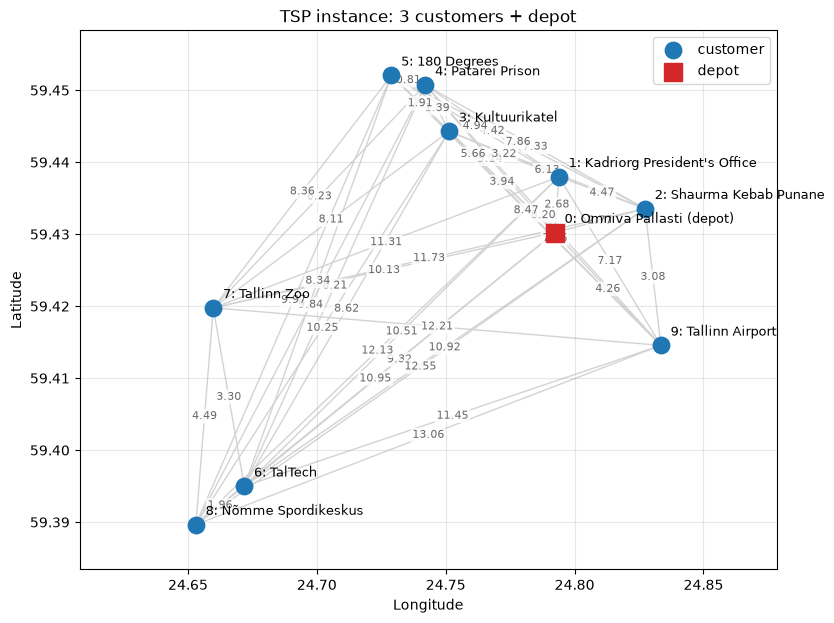

In [67]:
ins = load_instance(path="tallinn_osrm_matrix.json", n=10, symmetric=True)
plot = plot_network(ins, show_distances=True, depot=0, title="TSP instance: 3 customers + depot")

## Symetrical approach

## The central path 
Since the three nods are in a circe, it is pointless to run the optimisation. Let's say that we will go through the inner circle as follows: 0; 3; 7

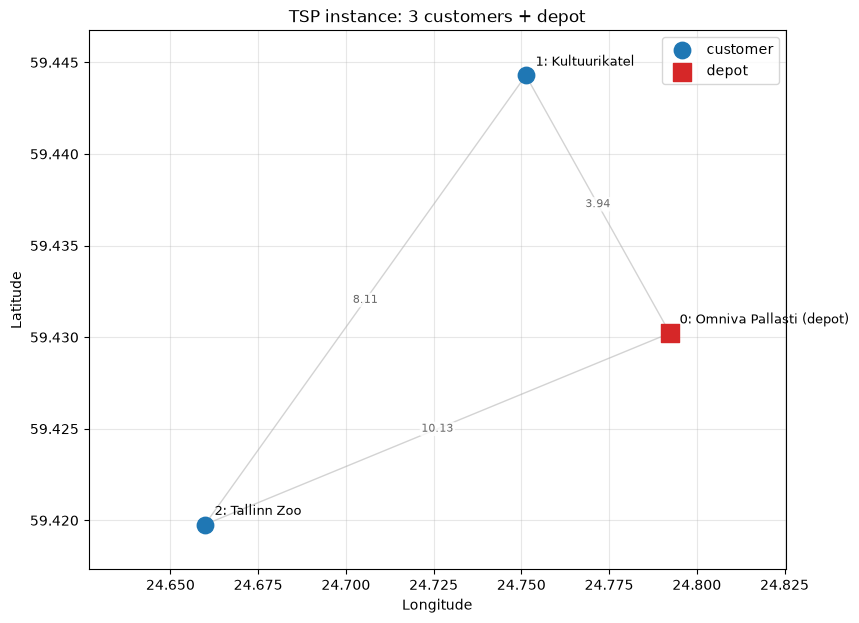

In [68]:
ins = load_instance(path="tallinn_osrm_matrix.json", nodes=[0, 3, 7], symmetric=True)
plot = plot_network(ins, show_distances=True, depot=0, title="TSP instance: 3 customers + depot")

The same applies to groups A and B.

## Group C
It contains the nodes 0; 1; 2; 9

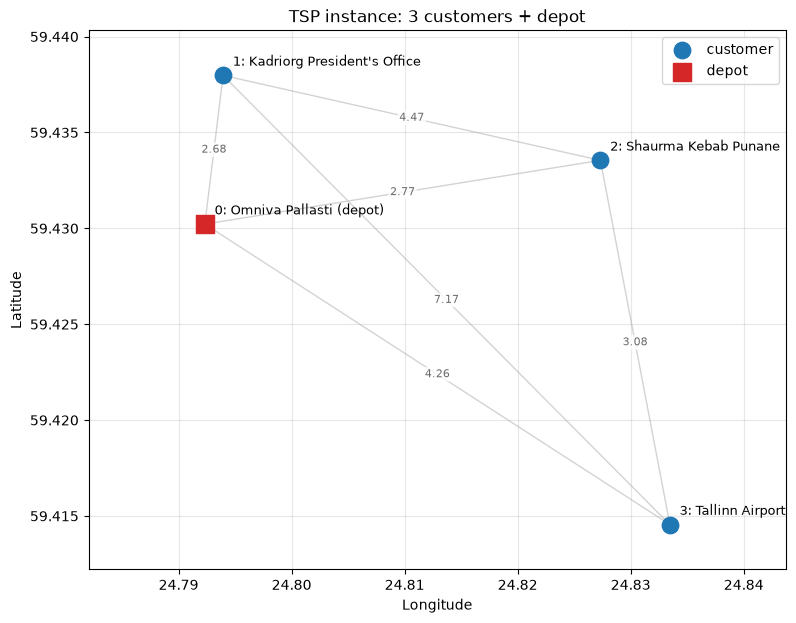

In [69]:
inst = load_instance("tallinn_osrm_matrix.json", nodes = [0, 1, 2, 9], symmetric=True)
plot = plot_network(inst, show_distances=True, depot=0, title="TSP instance: 3 customers + depot")

4 locations → 9 qubits, 39 Pauli terms, penalty = 20
Optimal routes (14.488 km): [(0, 1, 2, 3, 0), (0, 3, 2, 1, 0)]


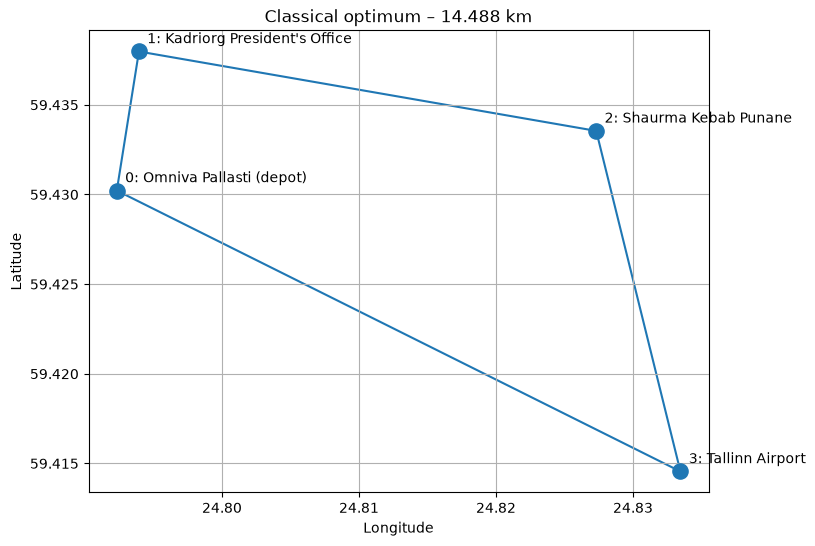

In [70]:
enc = PositionEncoding(inst.n)
qp = build_qp(inst.distances, enc, name="Omniva_TSP")
model = to_hamiltonian(qp, enc, penalty=20)
optimal_routes, optimal_length = brute_force(inst.distances)

print(f"{inst.n} locations → {enc.num_qubits} qubits, {len(model.operator)} Pauli terms, penalty = {model.penalty:g}")
print(f"Optimal routes ({optimal_length:.3f} km):", optimal_routes)
plot_route(inst, optimal_routes[0], f"Classical optimum – {optimal_length:.3f} km")
plt.show()

## Implementing the asymetrical solution
## Group A
The group off 7; 6; 8

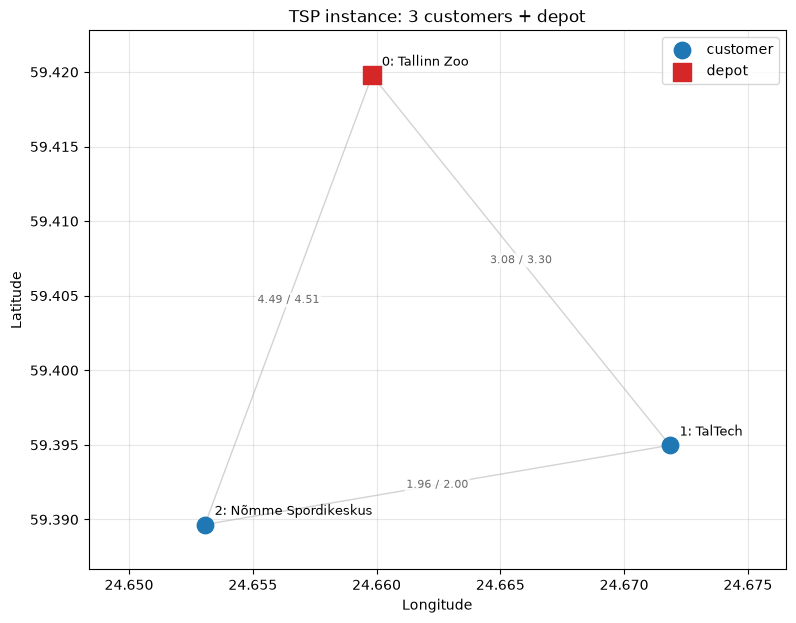

In [71]:
inst = load_instance("tallinn_osrm_matrix.json", nodes = [7, 6, 8])
plot = plot_network(inst, show_distances=True, title="TSP instance: 3 customers + depot")

3 locations → 4 qubits, 10 Pauli terms, penalty = 20
Optimal routes (9.557 km): [(0, 1, 2, 0)]


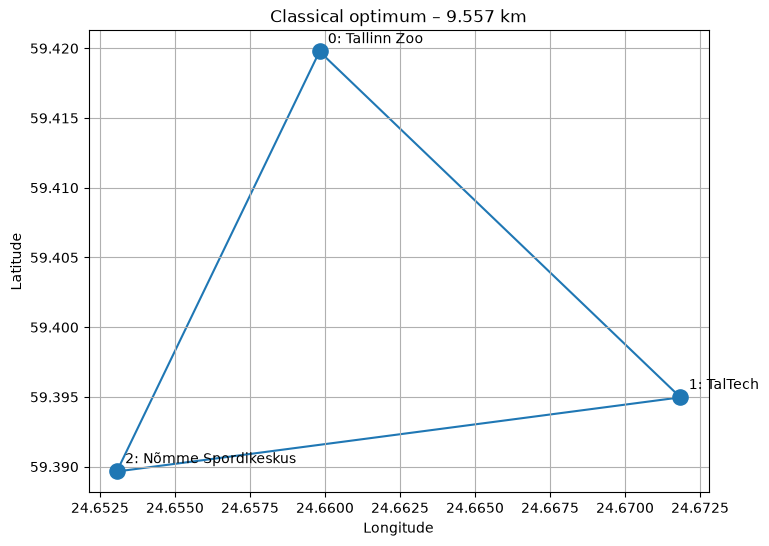

In [72]:
enc = PositionEncoding(inst.n)
qp = build_qp(inst.distances, enc, name="Omniva_TSP")
model = to_hamiltonian(qp, enc, penalty=20)
optimal_routes, optimal_length = brute_force(inst.distances)

print(f"{inst.n} locations → {enc.num_qubits} qubits, {len(model.operator)} Pauli terms, penalty = {model.penalty:g}")
print(f"Optimal routes ({optimal_length:.3f} km):", optimal_routes)
plot = plot_route(inst, optimal_routes[0], f"Classical optimum – {optimal_length:.3f} km")

## Group B
The group off 3; 4; 5

196 evaluations, converged: True (Return from COBYLA because the trust region radius reaches its lower bound.)
Optimal parameters: [1.254  0.7125 0.7987 0.3775]
=== QAOA RESULT ===
Classical optimum:            9.557 km
P(valid route):               91.58%
P(optimal route):             45.79%
P(optimum | valid):           50.00%   (random choice: 50.00%)
Most likely valid route:      0 → 1 → 2 → 0  9.557 km, p = 45.79%
Most likely bitstring:        0 → 1 → 2 → 0  p = 45.79%


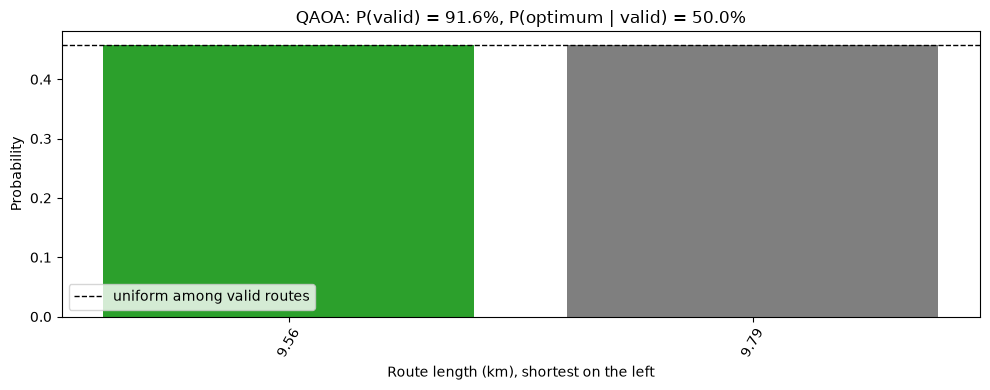

In [73]:
ansatz = build_ansatz(model.operator, reps=2)
run = optimize(ansatz, model.operator, maxiter=200)
print(f"{len(run.history)} evaluations, converged: {run.converged} ({run.message})")
print("Optimal parameters:", np.round(run.params, 4))

result = evaluate(probabilities(ansatz, run.params), inst.distances, enc)
print(result)
plot_distribution(result)
plt.show()

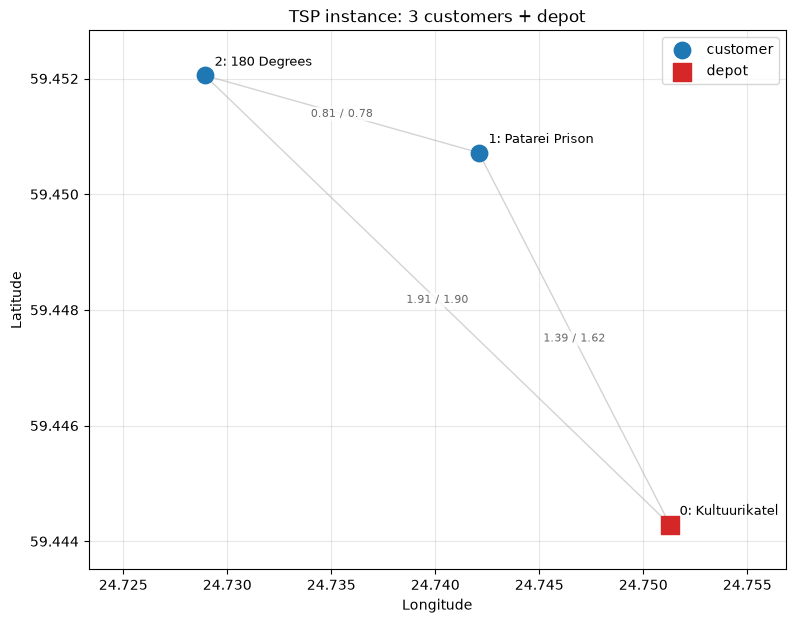

In [74]:
inst = load_instance("tallinn_osrm_matrix.json", nodes = [3, 4, 5])
plot = plot_network(inst, show_distances=True, depot=0, title="TSP instance: 3 customers + depot")

3 locations → 4 qubits, 10 Pauli terms, penalty = 20
Optimal routes (4.089 km): [(0, 1, 2, 0)]


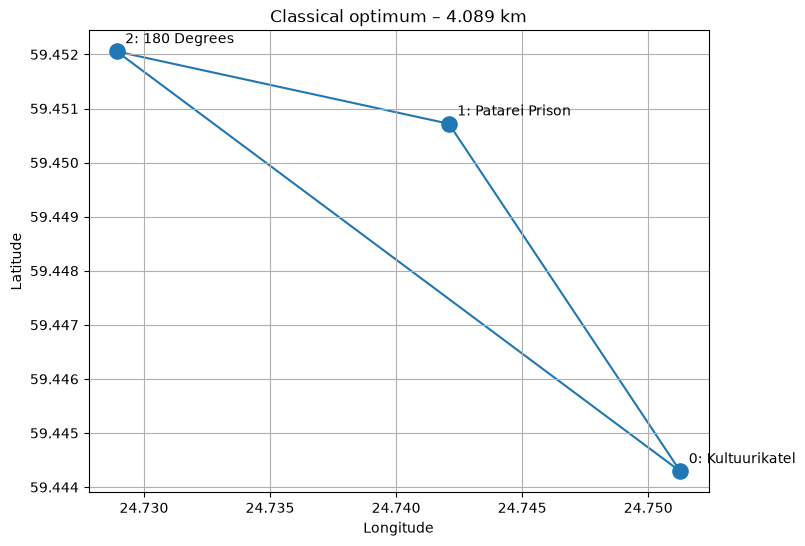

In [75]:
enc = PositionEncoding(inst.n)
qp = build_qp(inst.distances, enc, name="Omniva_TSP")
model = to_hamiltonian(qp, enc, penalty=20)
optimal_routes, optimal_length = brute_force(inst.distances)

print(f"{inst.n} locations → {enc.num_qubits} qubits, {len(model.operator)} Pauli terms, penalty = {model.penalty:g}")
print(f"Optimal routes ({optimal_length:.3f} km):", optimal_routes)
plot = plot_route(inst, optimal_routes[0], f"Classical optimum – {optimal_length:.3f} km")

140 evaluations, converged: True (Return from COBYLA because the trust region radius reaches its lower bound.)
Optimal parameters: [1.1957 0.7723 0.7906 0.3876]
=== QAOA RESULT ===
Classical optimum:            4.089 km
P(valid route):               98.49%
P(optimal route):             49.25%
P(optimum | valid):           50.01%   (random choice: 50.00%)
Most likely valid route:      0 → 1 → 2 → 0  4.089 km, p = 49.25%
Most likely bitstring:        0 → 1 → 2 → 0  p = 49.25%


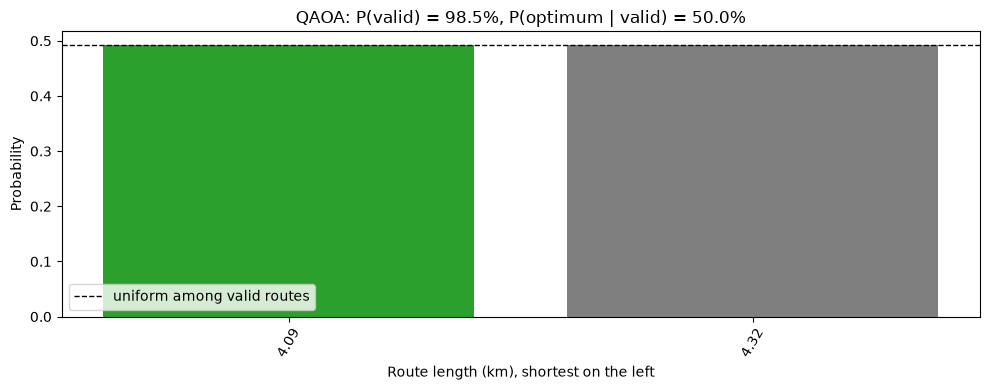

In [76]:
ansatz = build_ansatz(model.operator, reps=2)
run = optimize(ansatz, model.operator, maxiter=200)
print(f"{len(run.history)} evaluations, converged: {run.converged} ({run.message})")
print("Optimal parameters:", np.round(run.params, 4))

result = evaluate(probabilities(ansatz, run.params), inst.distances, enc)
print(result)
plot_distribution(result)
plt.show()

## Group C
The group off 0; 1; 2; 9

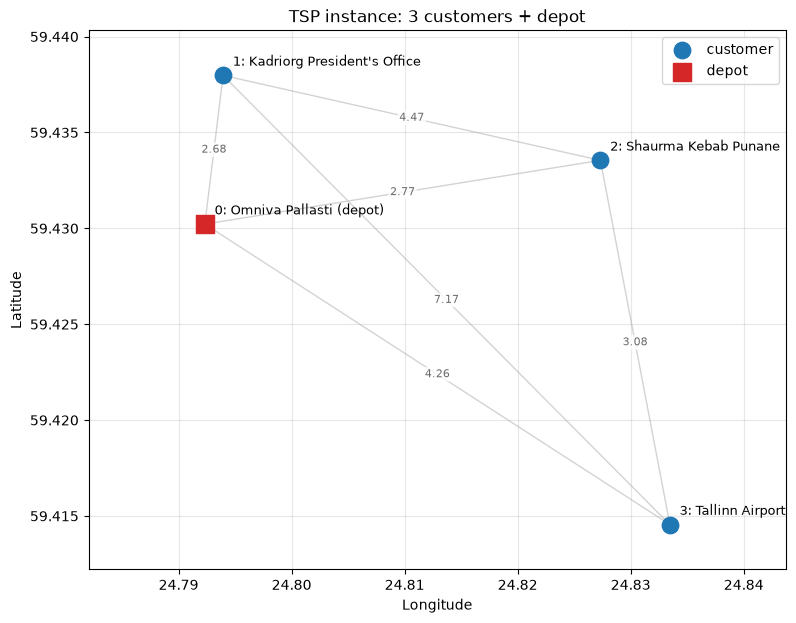

In [77]:
inst = load_instance("tallinn_osrm_matrix.json", nodes = [0, 1, 2, 9], symmetric=True)
plot = plot_network(inst, show_distances=True, depot=0, title="TSP instance: 3 customers + depot")

4 locations → 9 qubits, 39 Pauli terms, penalty = 20
Optimal routes (14.488 km): [(0, 1, 2, 3, 0), (0, 3, 2, 1, 0)]


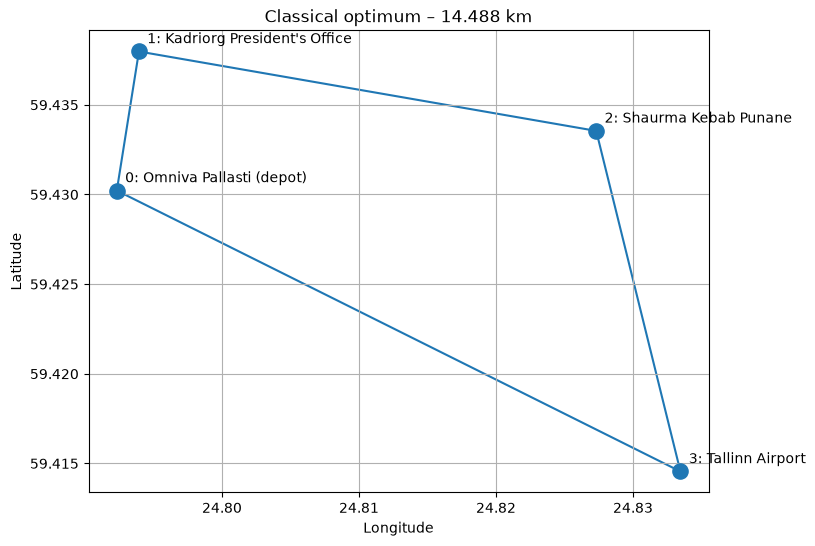

In [78]:
enc = PositionEncoding(inst.n)
qp = build_qp(inst.distances, enc, name="Omniva_TSP")
model = to_hamiltonian(qp, enc, penalty=20)
optimal_routes, optimal_length = brute_force(inst.distances)

print(f"{inst.n} locations → {enc.num_qubits} qubits, {len(model.operator)} Pauli terms, penalty = {model.penalty:g}")
print(f"Optimal routes ({optimal_length:.3f} km):", optimal_routes)
plot = plot_route(inst, optimal_routes[0], f"Classical optimum – {optimal_length:.3f} km")

200 evaluations, converged: False (Return from COBYLA because the objective function has been evaluated MAXFUN times.)
Optimal parameters: [1.211  1.4863 0.4264 0.2481]
=== QAOA RESULT ===
Classical optimum:            14.488 km
P(valid route):               14.71%
P(optimal route):             5.07%
P(optimum | valid):           34.49%   (random choice: 33.33%)
Most likely valid route:      0 → 1 → 2 → 3 → 0  14.488 km, p = 2.54%
Most likely bitstring:        0 → 3 → 2 → 1 → 0  p = 2.54%


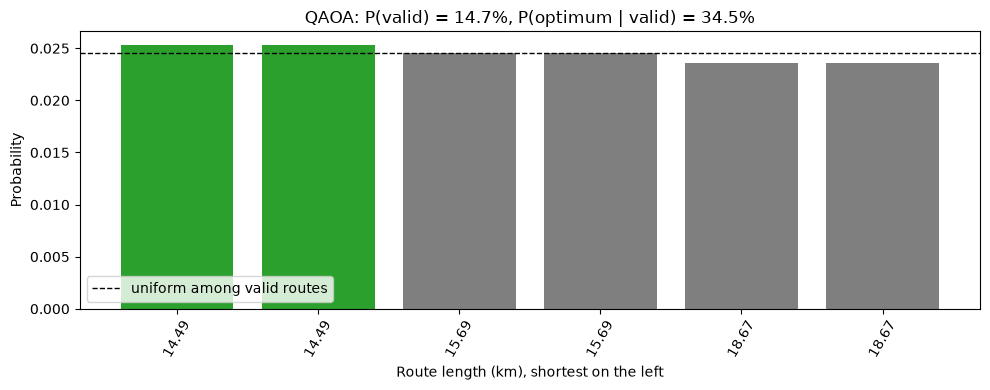

In [79]:
ansatz = build_ansatz(model.operator, reps=2)
run = optimize(ansatz, model.operator, maxiter=200)
print(f"{len(run.history)} evaluations, converged: {run.converged} ({run.message})")
print("Optimal parameters:", np.round(run.params, 4))

result = evaluate(probabilities(ansatz, run.params), inst.distances, enc)
print(result)
plot_distribution(result)
plt.show()

## 9. example: 5 Tallinn locations

Skipped when another notebook sets `RUN_EXAMPLE = False` and loads this one with `%run -i tsp_library.ipynb`.

5 locations → 16 qubits, 100 Pauli terms, penalty = 20
Optimal routes (16.983 km): [(0, 2, 1, 3, 4, 0), (0, 2, 1, 4, 3, 0), (0, 3, 4, 1, 2, 0), (0, 4, 3, 1, 2, 0)]


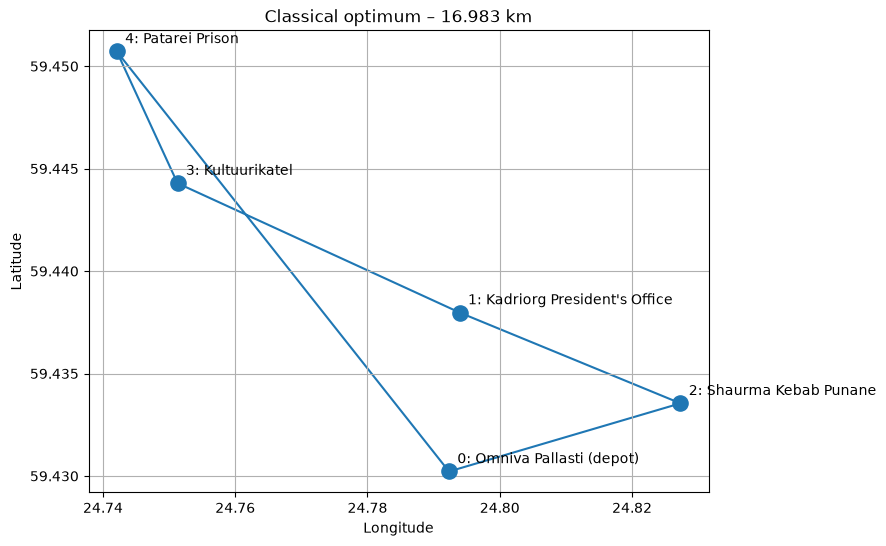

In [80]:
RUN_EXAMPLE = globals().get("RUN_EXAMPLE", True)

if RUN_EXAMPLE:
    inst = load_instance("tallinn_osrm_matrix.json", n=5, symmetric=True)
    enc = PositionEncoding(inst.n)
    qp = build_qp(inst.distances, enc, name="Omniva_TSP")
    model = to_hamiltonian(qp, enc, penalty=20)
    optimal_routes, optimal_length = brute_force(inst.distances)

    print(f"{inst.n} locations → {enc.num_qubits} qubits, {len(model.operator)} Pauli terms, penalty = {model.penalty:g}")
    print(f"Optimal routes ({optimal_length:.3f} km):", optimal_routes)
    plot_route(inst, optimal_routes[0], f"Classical optimum – {optimal_length:.3f} km")
    plt.show()

200 evaluations, converged: False (Return from COBYLA because the objective function has been evaluated MAXFUN times.)
Optimal parameters: [1.1031 1.5537 0.5099 0.4021]
=== QAOA RESULT ===
Classical optimum:            16.983 km
P(valid route):               2.55%
P(optimal route):             0.45%
P(optimum | valid):           17.70%   (random choice: 16.67%)
Most likely valid route:      0 → 4 → 3 → 1 → 2 → 0  16.983 km, p = 0.11%
Most likely bitstring:        INVALID  p = 0.28%


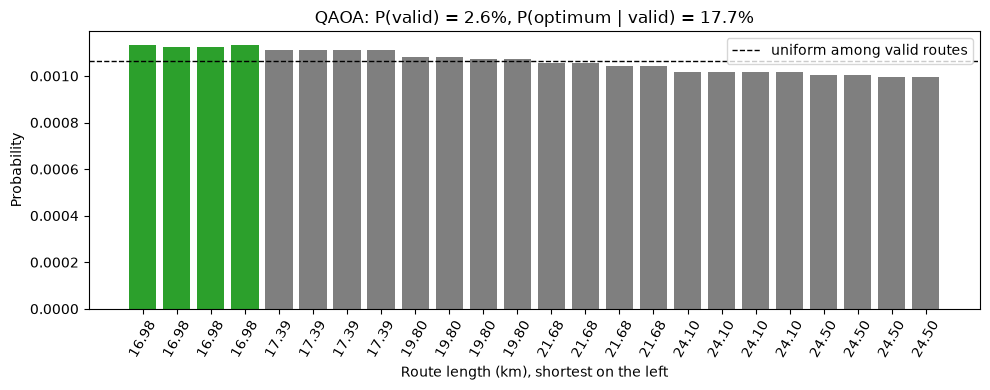

In [81]:
if RUN_EXAMPLE:
    ansatz = build_ansatz(model.operator, reps=2)
    run = optimize(ansatz, model.operator, maxiter=200)
    print(f"{len(run.history)} evaluations, converged: {run.converged} ({run.message})")
    print("Optimal parameters:", np.round(run.params, 4))

    result = evaluate(probabilities(ansatz, run.params), inst.distances, enc)
    print(result)
    plot_distribution(result)
    plt.show()